In [18]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## EN4554 Assignment 2 - Convolutional Neural Networks

**Name:** Jayarathne H.A.C.N.
**Index number:** 220252U


### 0. Setup

In [19]:
import os, time, json, math, copy, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

In [20]:
SEED = 0
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = device.type == 'cuda'       
torch.backends.cudnn.benchmark = True
import warnings
warnings.filterwarnings('ignore', message='Detected call of `lr_scheduler.step()` before `optimizer.step()`')

DATA_DIR, RESULTS_DIR, FIG_DIR = 'data', 'results', 'figures'
os.makedirs(RESULTS_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

EPOCHS = dict(t1c=20, t2c=15, t3a=100, t3b=30, t4=20)

print('torch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

torch 2.13.0+cu126 | device: cuda | NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [21]:
# CIFAR-10: 45k / 5k split and per-channel normalisation with training statistics
train_full = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
CLASSES = train_full.classes
X_all = torch.tensor(train_full.data).permute(0, 3, 1, 2).float().div(255)   # (50000, 3, 32, 32) in [0, 1]
y_all = torch.tensor(train_full.targets)

perm = torch.randperm(len(y_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]

MEAN = X_all[tr_idx].mean(dim=(0, 2, 3))     # statistics from the 45k training images only
STD = X_all[tr_idx].std(dim=(0, 2, 3))
def normalize(x):
    return (x - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)

Xtr, ytr = normalize(X_all[tr_idx]).to(device), y_all[tr_idx].to(device)
Xva, yva = normalize(X_all[va_idx]).to(device), y_all[va_idx].to(device)
print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape))
print('channel mean', MEAN.numpy().round(4), '| channel std', STD.numpy().round(4))
print('val class counts', torch.bincount(yva.cpu()).tolist())

100.0%


train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
channel mean [0.4912 0.482  0.4464] | channel std [0.2472 0.2436 0.2617]
val class counts [482, 508, 494, 504, 532, 507, 502, 506, 498, 467]


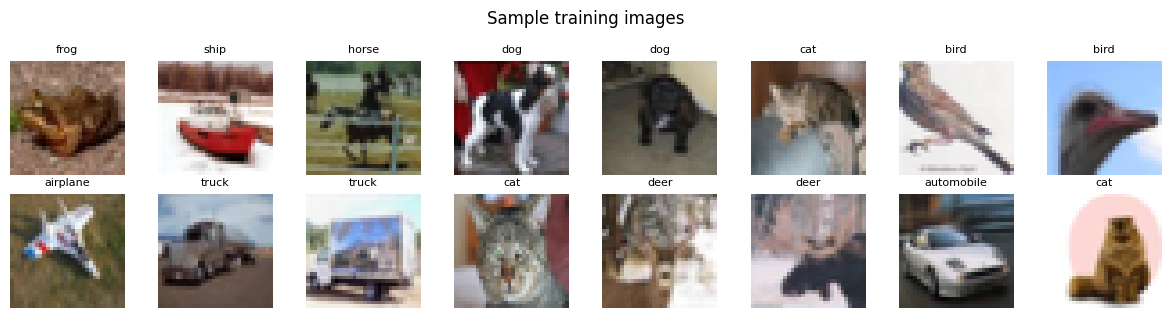

In [22]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, i in zip(axes.flat, range(16)):
    img = X_all[tr_idx[i]].permute(1, 2, 0).numpy()
    ax.imshow(img); ax.set_title(CLASSES[y_all[tr_idx[i]]], fontsize=8); ax.axis('off')
plt.suptitle('Sample training images'); plt.tight_layout(); plt.show()

In [23]:
def batches(X, y, bs, shuffle=True):
    idx = torch.randperm(len(y), device=X.device) if shuffle else torch.arange(len(y), device=X.device)
    for i in range(0, len(y), bs):
        j = idx[i:i + bs]
        yield X[j], y[j]

def flip_crop(x, pad=4):
    N, C, H, W = x.shape
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (N,), device=x.device)          # top-left corner of each crop
    j = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    rows = (i[:, None] + torch.arange(H, device=x.device))[:, None, :, None]    # (N,1,H,1)
    cols = (j[:, None] + torch.arange(W, device=x.device))[:, None, None, :]    # (N,1,1,W)
    n = torch.arange(N, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[n, c, rows, cols]

def cutout(x, size=16):
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N, 1, 1), device=x.device)
    cx = torch.randint(0, W, (N, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :, None]
    xs = torch.arange(W, device=x.device)[None, None, :]
    inside = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~inside)[:, None].to(x.dtype)

def mixup(x, y, alpha=1.0):
    lam = float(np.random.beta(alpha, alpha))
    p = torch.randperm(len(y), device=x.device)
    return lam * x + (1 - lam) * x[p], y, y[p], lam

def compose(*fs):
    return lambda x: x if not fs else compose(*fs[1:])(fs[0](x))

@torch.no_grad()
def evaluate(model, X, y, bs=1000, tta=False):
    model.eval(); loss, correct = 0.0, 0
    for xb, yb in batches(X, y, bs, shuffle=False):
        with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            out = model(xb).float()
            if tta:                                    # average with the horizontally-flipped image
                out = (out + model(xb.flip(3)).float()) / 2
        loss += F.cross_entropy(out, yb, reduction='sum').item()
        correct += (out.argmax(1) == yb).sum().item()
    return loss / len(y), correct / len(y)

def train_model(model, opt, X, y, epochs, bs=128, sched=None, augment=None, mixup_alpha=0.0,
                label_smoothing=0.0, amp=AMP, eval_train=False, val=(None, None), log_every=5, tag=''):
    """Generic loop. sched is stepped every iteration. If eval_train, the train accuracy is measured on the
    clean training set in eval mode (needed for Task 3a), otherwise it is the running accuracy on augmented batches."""
    scaler = torch.amp.GradScaler(device.type, enabled=amp)
    H = {k: [] for k in ['iter_loss', 'train_loss', 'train_acc', 'val_loss', 'val_acc']}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); losses, correct = [], 0
        for xb, yb in batches(X, y, bs):
            if augment is not None:
                xb = augment(xb)
            with torch.autocast(device.type, dtype=torch.float16, enabled=amp):
                if mixup_alpha > 0:
                    xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
                    out = model(xb)
                    loss = lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing) \
                         + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing)
                else:
                    out = model(xb)
                    loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            if sched is not None:
                sched.step()
            losses.append(loss.detach().float())
            correct += (out.argmax(1) == yb).sum()
        ep_losses = torch.stack(losses).tolist()
        H['iter_loss'] += ep_losses
        H['train_loss'].append(float(np.mean(ep_losses)))
        H['train_acc'].append(evaluate(model, X, y)[1] if eval_train else correct.item() / len(y))
        if val[0] is not None:
            vl, va = evaluate(model, *val)
            H['val_loss'].append(vl); H['val_acc'].append(va)
        if ep % log_every == 0 or ep == epochs:
            print(f'{tag} ep {ep:3d} | train loss {H["train_loss"][-1]:.4f} acc {H["train_acc"][-1]:.4f}'
                  + (f' | val loss {H["val_loss"][-1]:.4f} acc {H["val_acc"][-1]:.4f}' if H['val_acc'] else '')
                  + f' | {time.time() - t0:.0f}s')
    H['time'] = time.time() - t0
    return H

def warmup_cosine(opt, total_steps, warmup_steps=0):
    """Per-iteration schedule: linear warm-up from ~0 to the base lr, then cosine decay to 0."""
    def f(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        return 0.5 * (1 + math.cos(math.pi * (step - warmup_steps) / max(1, total_steps - warmup_steps)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def cached(name, fn):
    """Run fn() once and store its result (a JSON-serialisable dict) in results/name.json."""
    path = os.path.join(RESULTS_DIR, name + '.json')
    if os.path.exists(path):
        with open(path) as f:
            print(f'[loaded cached result: {path}]')
            return json.load(f)
    out = fn()
    with open(path, 'w') as f:
        json.dump(out, f)
    return out

def smooth(v, k=50):
    v = np.asarray(v, dtype=float)
    return np.convolve(v, np.ones(k) / k, mode='valid') if len(v) > k else v

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name + '.png'), dpi=150, bbox_inches='tight')

def n_params(model):
    return sum(p.numel() for p in model.parameters())